# India Tourism ML Project — Assigned Regression and Clustering Components

This supplementary notebook completes the methods listed in Problem 73. Keep the original forecasting notebook for EDA, ADF, SARIMA, Holt-Winters and the seasonal-naïve baseline. Place these CSV files in the same folder as this notebook:

- `India_Monthly_FTA_2019_2024.csv`
- `India_Tourism_Statistics_2024_Clustering_Cleaned.csv`

**Important data limitation:** the official 2024 compendium provides monthly total FTAs and nationality-wise quarterly distributions (plus peak/lean month summaries for the top 15 source markets), but not a full 12-month-by-country matrix for all countries. Therefore, the country clustering below uses the available quarterly seasonal profiles as a transparent proxy for the assigned monthly-profile clustering.

## 1. Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error,
    r2_score,
    silhouette_score
)
from sklearn.cluster import KMeans

RANDOM_STATE = 42

## 2. Assigned regression models

We use a chronological split: January 2019–December 2023 for training (60 observations) and January–December 2024 for testing (12 observations). The feature set includes a time trend, COVID-period and recovery indicators, and monthly seasonal dummy variables. Scaling is fitted inside each pipeline to avoid leakage.

In [2]:
# Load and sort monthly FTA data
monthly_df = pd.read_csv('India_Monthly_FTA_2019_2024.csv')
monthly_df['date'] = pd.to_datetime(monthly_df['date'])
monthly_df = monthly_df.sort_values('date').reset_index(drop=True)

# Feature engineering
monthly_df['trend'] = np.arange(len(monthly_df))
monthly_df['covid_period'] = monthly_df['year'].between(2020, 2021).astype(int)
monthly_df['recovery_period'] = (monthly_df['year'] >= 2022).astype(int)

# Seasonal dummy variables (January is the reference month)
month_dummies = pd.get_dummies(
    monthly_df['date'].dt.month,
    prefix='month',
    drop_first=True,
    dtype=int
)

X = pd.concat(
    [monthly_df[['trend', 'covid_period', 'recovery_period']], month_dummies],
    axis=1
)
y = monthly_df['foreign_tourist_arrivals']

X_train, X_test = X.iloc[:60], X.iloc[60:]
y_train, y_test = y.iloc[:60], y.iloc[60:]

print('Training observations:', len(X_train))
print('Testing observations:', len(X_test))
print('Training period:', monthly_df['date'].iloc[0], 'to', monthly_df['date'].iloc[59])
print('Testing period:', monthly_df['date'].iloc[60], 'to', monthly_df['date'].iloc[-1])

Training observations: 60
Testing observations: 12
Training period: 2019-01-01 00:00:00 to 2023-12-01 00:00:00
Testing period: 2024-01-01 00:00:00 to 2024-12-01 00:00:00


### 2.1 Fit Linear, Polynomial, Ridge and k-NN regression

Ridge and k-NN hyperparameters are selected using expanding-window `TimeSeriesSplit` cross-validation on the training period only. Polynomial regression uses degree-2 features.

In [3]:
tscv = TimeSeriesSplit(n_splits=5)

models = {
    'Linear Regression': Pipeline([
        ('scale', StandardScaler()),
        ('model', LinearRegression())
    ]),
    'Polynomial Regression (degree 2)': Pipeline([
        ('poly', PolynomialFeatures(degree=2, include_bias=False)),
        ('scale', StandardScaler()),
        ('model', LinearRegression())
    ])
}

# Ridge: tune regularization strength using training folds only
ridge_search = GridSearchCV(
    Pipeline([
        ('scale', StandardScaler()),
        ('model', Ridge())
    ]),
    param_grid={'model__alpha': [0.01, 0.1, 1, 10, 100, 1000]},
    cv=tscv,
    scoring='neg_root_mean_squared_error'
)
ridge_search.fit(X_train, y_train)
models['Ridge Regression'] = ridge_search.best_estimator_

# k-NN: scale features and tune k / weighting
knn_search = GridSearchCV(
    Pipeline([
        ('scale', StandardScaler()),
        ('model', KNeighborsRegressor())
    ]),
    param_grid={
        'model__n_neighbors': [3, 5, 7, 9],
        'model__weights': ['uniform', 'distance']
    },
    cv=tscv,
    scoring='neg_root_mean_squared_error'
)
knn_search.fit(X_train, y_train)
models['k-NN Regression'] = knn_search.best_estimator_

print('Best Ridge parameters:', ridge_search.best_params_)
print('Best k-NN parameters:', knn_search.best_params_)
print('Ridge CV RMSE:', round(-ridge_search.best_score_, 2))
print('k-NN CV RMSE:', round(-knn_search.best_score_, 2))

Best Ridge parameters: {'model__alpha': 10}
Best k-NN parameters: {'model__n_neighbors': 7, 'model__weights': 'uniform'}
Ridge CV RMSE: 371653.59
k-NN CV RMSE: 323731.43


### 2.2 Evaluate against the seasonal-naïve baseline

For the baseline, each month in 2024 is predicted using the corresponding month in 2023. Metrics: MAE, RMSE, R² and MAPE.

In [4]:
regression_predictions = pd.DataFrame({
    'date': monthly_df['date'].iloc[60:].values,
    'Actual_Arrivals': y_test.values
})
regression_metrics = []

for name, model in models.items():
    model.fit(X_train, y_train)
    prediction = model.predict(X_test)
    regression_predictions[name] = prediction

    regression_metrics.append({
        'Model': name,
        'MAE': mean_absolute_error(y_test, prediction),
        'RMSE': np.sqrt(mean_squared_error(y_test, prediction)),
        'R2': r2_score(y_test, prediction),
        'MAPE (%)': mean_absolute_percentage_error(y_test, prediction) * 100
    })

# Seasonal-naive baseline: same month in the previous year
seasonal_naive = monthly_df['foreign_tourist_arrivals'].iloc[48:60].to_numpy()
regression_predictions['Seasonal Naive'] = seasonal_naive

regression_metrics.append({
    'Model': 'Seasonal Naive baseline',
    'MAE': mean_absolute_error(y_test, seasonal_naive),
    'RMSE': np.sqrt(mean_squared_error(y_test, seasonal_naive)),
    'R2': r2_score(y_test, seasonal_naive),
    'MAPE (%)': mean_absolute_percentage_error(y_test, seasonal_naive) * 100
})

regression_metrics_df = pd.DataFrame(regression_metrics).sort_values('MAPE (%)')
print(regression_metrics_df.round(2).to_string(index=False))
regression_predictions.to_csv('Regression_2024_Predictions.csv', index=False)
regression_metrics_df.to_csv('Regression_Model_Comparison.csv', index=False)

                           Model       MAE      RMSE    R2  MAPE (%)
         Seasonal Naive baseline  43253.83  58173.06  0.85      4.89
               Linear Regression  51318.60  59543.55  0.84      5.96
                Ridge Regression 217326.72 223503.46 -1.22     26.02
                 k-NN Regression 297675.96 303924.32 -3.11     35.82
Polynomial Regression (degree 2) 393637.47 402087.60 -6.19     48.69


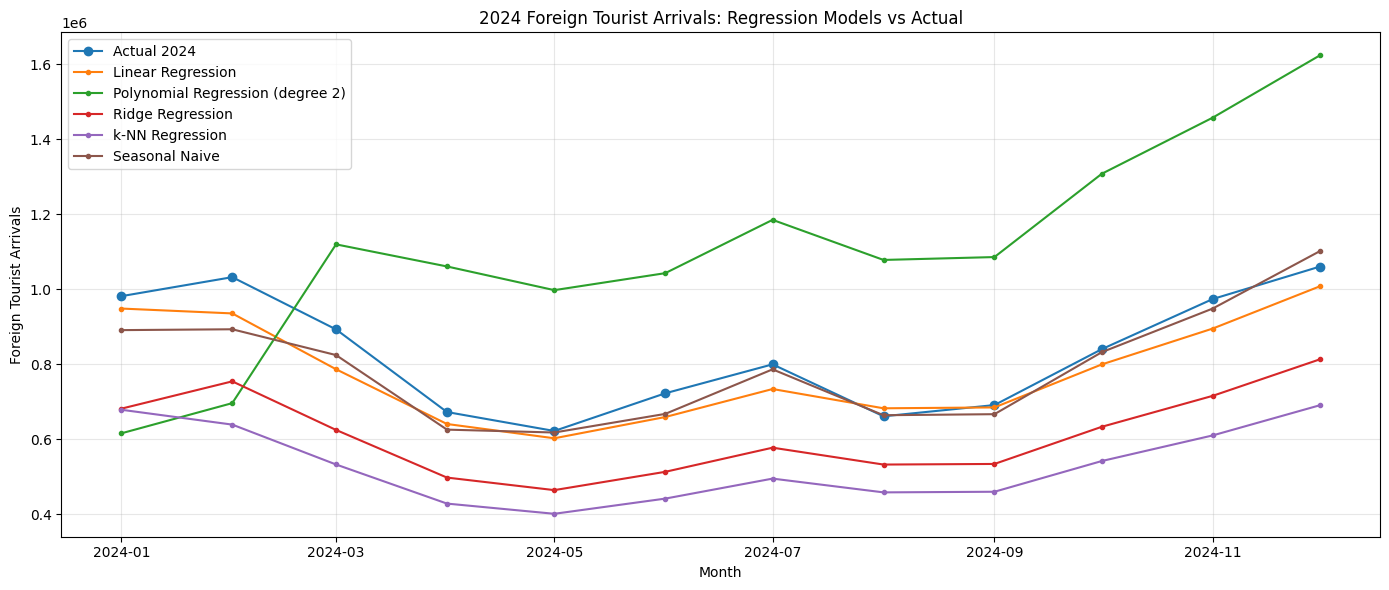

In [5]:
# Actual vs predictions for assigned regression methods
plt.figure(figsize=(14, 6))
plt.plot(monthly_df['date'].iloc[60:], y_test, marker='o', label='Actual 2024')
for col in ['Linear Regression', 'Polynomial Regression (degree 2)', 'Ridge Regression', 'k-NN Regression', 'Seasonal Naive']:
    plt.plot(regression_predictions['date'], regression_predictions[col], marker='.', label=col)
plt.title('2024 Foreign Tourist Arrivals: Regression Models vs Actual')
plt.xlabel('Month')
plt.ylabel('Foreign Tourist Arrivals')
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

### Regression interpretation

In the completed run, the seasonal-naïve baseline achieved the lowest error (MAE 43,253.83; RMSE 58,173.06; R² 0.85; MAPE 4.89%). Among the four assigned regression models, Linear Regression performed best (MAE 51,318.60; RMSE 59,543.55; R² 0.84; MAPE 5.96%). Polynomial, Ridge and k-NN performed worse on this 2024 holdout. The degree-2 polynomial model extrapolated poorly, illustrating why more complex models are not automatically better.

## 3. Nationality-wise seasonal clustering with K-Means

The available 2024 country-level dataset contains quarterly percentage shares. The clustering features are the four quarter percentages only; total arrivals are used to identify very low-volume country profiles, not as a clustering feature. Countries with fewer than 100 arrivals are excluded from the primary analysis because their percentages are based on very small counts and can be unstable. This leaves 183 countries/territories from 209.

In [6]:
cluster_df = pd.read_csv('India_Tourism_Statistics_2024_Clustering_Cleaned.csv')
quarter_cols = [c for c in cluster_df.columns if 'Quarters' in c]

# Keep profiles with at least 100 annual arrivals for the primary analysis
cluster_df = cluster_df[cluster_df['Arrivals (In Numbers)'] >= 100].copy()
cluster_df = cluster_df.reset_index(drop=True)
X_cluster = cluster_df[quarter_cols].astype(float)

print('Countries in original cleaned data:', 209)
print('Countries retained:', len(cluster_df))
print('Countries excluded (<100 arrivals):', 209 - len(cluster_df))
print('Quarter-share row sums (min/max):',
      round(X_cluster.sum(axis=1).min(), 2),
      round(X_cluster.sum(axis=1).max(), 2))

Countries in original cleaned data: 209
Countries retained: 183
Countries excluded (<100 arrivals): 26
Quarter-share row sums (min/max): 99.99 100.01


### 3.1 Elbow and silhouette analysis

The quarterly features are all percentages on the same scale, so we use percentage-point distances directly rather than scaling each quarter independently. Compare K from 2 to 8 using inertia and silhouette score.

 K    Inertia  Silhouette               Cluster sizes
 2 18932.8609      0.3175                      94, 89
 3 14390.6606      0.3387                 61, 14, 108
 4 11970.5858      0.3142               98, 61, 1, 23
 5  9822.6410      0.2946            6, 54, 31, 91, 1
 6  8144.9773      0.2844        67, 19, 21, 1, 6, 69
 7  6965.1024      0.3064     11, 72, 9, 63, 6, 1, 21
 8  6153.6070      0.2903 46, 26, 23, 11, 1, 62, 6, 8


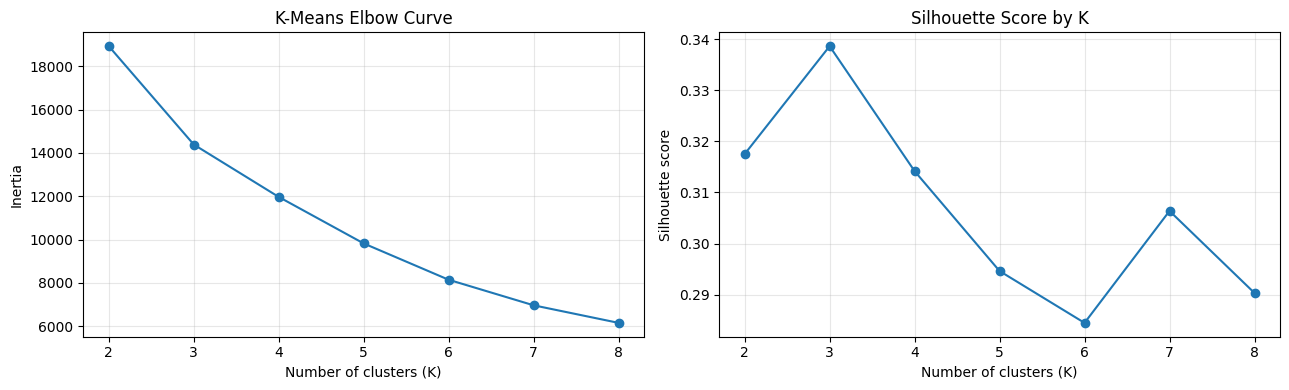

In [7]:
k_values = range(2, 9)
inertias = []
silhouettes = []
cluster_sizes = []

for k in k_values:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=50)
    labels = km.fit_predict(X_cluster)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_cluster, labels))
    cluster_sizes.append(', '.join(map(str, np.bincount(labels))))

kmeans_evaluation = pd.DataFrame({
    'K': list(k_values),
    'Inertia': inertias,
    'Silhouette': silhouettes,
    'Cluster sizes': cluster_sizes
})
print(kmeans_evaluation.round(4).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(list(k_values), inertias, marker='o')
axes[0].set_title('K-Means Elbow Curve')
axes[0].set_xlabel('Number of clusters (K)')
axes[0].set_ylabel('Inertia')
axes[1].plot(list(k_values), silhouettes, marker='o')
axes[1].set_title('Silhouette Score by K')
axes[1].set_xlabel('Number of clusters (K)')
axes[1].set_ylabel('Silhouette score')
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 3.2 Fit and compare K=2 and K=3

K=3 had a slightly higher silhouette score in the completed run (0.3387) than K=2 (0.3175). The labels below are reordered so Cluster 1 has the highest Q1 mean, making interpretation consistent.

In [8]:
cluster_profiles = []
for k in [2, 3]:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=50)
    labels = km.fit_predict(X_cluster) + 1
    label_col = f'Cluster_K{k}'
    cluster_df[label_col] = labels

    # Reorder labels by descending Q1 centroid for consistent interpretation
    means = cluster_df.groupby(label_col)[quarter_cols].mean()
    order = means[quarter_cols[0]].sort_values(ascending=False).index.tolist()
    remap = {old: new + 1 for new, old in enumerate(order)}
    cluster_df[label_col] = cluster_df[label_col].map(remap)

    sil = silhouette_score(X_cluster, cluster_df[label_col])
    profile = cluster_df.groupby(label_col)[quarter_cols].mean()
    counts = cluster_df[label_col].value_counts().sort_index()

    print(f'\nK={k}; silhouette={sil:.4f}')
    for cluster_id in profile.index:
        print(f'Cluster {cluster_id}: {counts.loc[cluster_id]} countries')
        print(profile.loc[cluster_id].round(2).to_dict())
        cluster_profiles.append({
            'K': k,
            'Cluster': cluster_id,
            'Country_Count': counts.loc[cluster_id],
            **{f'Q{i+1}_percent': profile.loc[cluster_id, quarter_cols[i]] for i in range(4)},
            'Silhouette_Score': sil
        })

cluster_profiles_df = pd.DataFrame(cluster_profiles)
cluster_df.to_csv('India_Tourism_Clustering_Results.csv', index=False)
cluster_profiles_df.to_csv('Clustering_Profiles.csv', index=False)
kmeans_evaluation.to_csv('KMeans_Evaluation.csv', index=False)


K=2; silhouette=0.3175
Cluster 1: 94 countries
{'1st Quarters (January-March) (In Percentage)': 31.9, '2nd Quarters (April-June) (In Percentage)': 17.83, '3rd Quarters (July-September) (In Percentage)': 19.22, '4th Quarters (October-December) (In Percentage)': 31.05}
Cluster 2: 89 countries
{'1st Quarters (January-March) (In Percentage)': 23.58, '2nd Quarters (April-June) (In Percentage)': 19.95, '3rd Quarters (July-September) (In Percentage)': 29.46, '4th Quarters (October-December) (In Percentage)': 27.0}

K=3; silhouette=0.3387
Cluster 1: 61 countries
{'1st Quarters (January-March) (In Percentage)': 33.49, '2nd Quarters (April-June) (In Percentage)': 16.05, '3rd Quarters (July-September) (In Percentage)': 18.01, '4th Quarters (October-December) (In Percentage)': 32.45}
Cluster 2: 108 countries
{'1st Quarters (January-March) (In Percentage)': 26.24, '2nd Quarters (April-June) (In Percentage)': 21.04, '3rd Quarters (July-September) (In Percentage)': 25.4, '4th Quarters (October-Decem

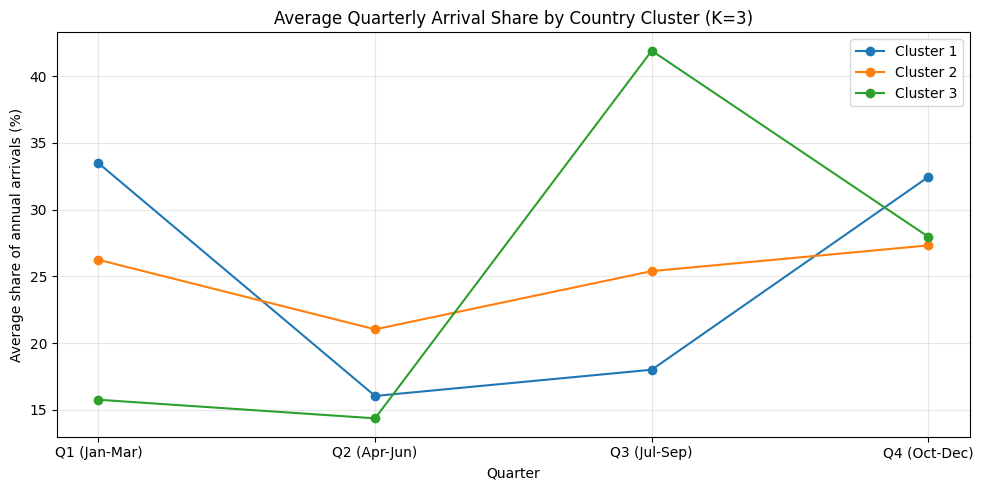

In [9]:
# Plot the K=3 cluster seasonal profiles
k3_profile = cluster_df.groupby('Cluster_K3')[quarter_cols].mean()
short_names = ['Q1 (Jan-Mar)', 'Q2 (Apr-Jun)', 'Q3 (Jul-Sep)', 'Q4 (Oct-Dec)']

plt.figure(figsize=(10, 5))
for cluster_id, row in k3_profile.iterrows():
    plt.plot(short_names, row.values, marker='o', label=f'Cluster {cluster_id}')
plt.title('Average Quarterly Arrival Share by Country Cluster (K=3)')
plt.xlabel('Quarter')
plt.ylabel('Average share of annual arrivals (%)')
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

### Clustering interpretation and limitation

For the retained 183 countries, the K=3 run produced:

- Cluster 1: 61 countries; relatively higher Q1 and Q4 shares.
- Cluster 2: 108 countries; more balanced quarterly distribution.
- Cluster 3: 14 countries; strong Q3 concentration (about 41.90%).

The silhouette score of 0.3387 indicates moderate/weak separation, so these should be treated as exploratory seasonal groups rather than perfectly distinct market segments. The official compendium's full nationality-wise seasonal distribution is quarterly; the monthly table reports aggregate FTAs by month and the top 15 countries' peak/lean months, not a complete monthly-by-country matrix. State this limitation clearly in the report.

## 4. Final outputs

After running all cells, the notebook writes:

- `Regression_Model_Comparison.csv`
- `Regression_2024_Predictions.csv`
- `India_Tourism_Clustering_Results.csv`
- `Clustering_Profiles.csv`
- `KMeans_Evaluation.csv`

These outputs can be used to prepare the results tables and figures in the journal-format report.